# Churn at Fit.ly

## What is driving customers away, and what the business can do about it

## Summary

Fit.ly asked for a clear picture of what is driving churn, with a focus on engagement, support activity and plan type. I combined the three datasets (account information, customer support tickets and in-app activity) into one customer-level table and compared customers who churned with customers who stayed.

Key points:

- **27.2% of customers have churned** (97 of the 357 customers kept for the analysis).
- **Slow support is the strongest warning sign.** Customers whose tickets take more than 12 hours on average to resolve churn at **91.3%**, against **3.4%** for customers whose tickets are resolved faster.
- **Low engagement is the second warning sign.** Customers with no recorded activity in the app churn at **51.9%**, against **12.2%** for customers who used the app at least once.
- **Together these two factors cover 94 of the 97 churned customers.**
- **Plan type matters less than it first appears.** Free users churn the most (38.3%), but they are also the least engaged and wait longest for support. Within the same engagement level the gap between paid plans is small.

My recommendation is to set a 12-hour resolution target for support, to monitor it every month, and to re-engage customers who stop using the app before they cancel.

## 1. Data validation

The datasets come from three different teams, and the Lead Engineer confirmed that no cleaning or validation happens in the pipelines. I checked every column against the data dictionary and against the answers from the Product Manager and the Lead Engineer before starting the analysis.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", font_scale=1.1)
STAYED, CHURNED = "#4C72B0", "#DD8452"

BASE_URL = "https://s3.us-east-1.amazonaws.com/talent-assets.datacamp.com/"

def load(name):
    # Look for a local copy first (data/ folder), otherwise read the file from the source link
    for folder in ["data/", "../data/", ""]:
        try:
            return pd.read_csv(folder + name)
        except FileNotFoundError:
            continue
    return pd.read_csv(BASE_URL + name)

account = load("da_fitly_account_info.csv")
support = load("da_fitly_customer_support.csv")
activity = load("da_fitly_user_activity.csv")

for name, df in [("account_info", account), ("customer_support", support), ("user_activity", activity)]:
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")
    print("  columns:", list(df.columns))
    print("  missing values:", df.isna().sum().to_dict())
    print("  duplicated rows:", df.duplicated().sum())

account_info: 400 rows, 6 columns
  columns: ['customer_id', 'email', 'state', 'plan', 'plan_list_price', 'churn_status']
  missing values: {'customer_id': 0, 'email': 0, 'state': 0, 'plan': 0, 'plan_list_price': 0, 'churn_status': 286}
  duplicated rows: 0
customer_support: 918 rows, 7 columns
  columns: ['ticket_time', 'user_id', 'channel', 'topic', 'resolution_time_hours', 'state', 'comments']
  missing values: {'ticket_time': 0, 'user_id': 0, 'channel': 0, 'topic': 0, 'resolution_time_hours': 0, 'state': 0, 'comments': 872}
  duplicated rows: 0
user_activity: 445 rows, 3 columns
  columns: ['event_time', 'user_id', 'event_type']
  missing values: {'event_time': 0, 'user_id': 0, 'event_type': 0}
  duplicated rows: 0


The first check already shows three differences from the data dictionary:

- In `account_info` the churn column is called `churn_status`, not `churn`.
- `customer_support` has an extra column, `comments`, which is not in the data dictionary.
- The Product Manager mentioned a `signup_date` column, but it is not in the file. Without it I cannot measure customer tenure, so I flagged it as a gap for the data team.

There are no fully duplicated rows in any table.

### 1.1 GDPR deletion requests (all tables)

The Product Manager told us that Fit.ly receives GDPR "right to be forgotten" requests through customer support and must handle them properly. The `comments` column is empty for most tickets, but every non-empty comment is a data deletion request.

In [2]:
gdpr_tickets = support[support["comments"].notna()]
print("Tickets with a comment:", len(gdpr_tickets))
print("Customers who asked for deletion:", gdpr_tickets["user_id"].nunique())
print()
print(gdpr_tickets["comments"].value_counts().head(10))

Tickets with a comment: 46
Customers who asked for deletion: 43

comments
Wipe all data you hold.                 5
Requesting right to be forgotten.       4
Erase my data from your systems.        3
Request full personal data deletion.    3
Please erase my information.            3
Request account and data deletion.      3
GDPR erasure request submission.        3
Delete my information entirely.         3
Request deletion of all records.        3
Delete any data about me.               3
Name: count, dtype: int64


In [3]:
gdpr_ids = set(gdpr_tickets["user_id"])

# Customer IDs are stored as "C10000" in account_info and as 10000 elsewhere
account_ids = account["customer_id"].str.replace("C", "", regex=False).astype(int)

rows_before = {"account": len(account), "support": len(support), "activity": len(activity)}
account = account[~account_ids.isin(gdpr_ids)].copy()
support = support[~support["user_id"].isin(gdpr_ids)].copy()
activity = activity[~activity["user_id"].isin(gdpr_ids)].copy()
rows_after = {"account": len(account), "support": len(support), "activity": len(activity)}

print("Rows before:", rows_before)
print("Rows after: ", rows_after)

Rows before: {'account': 400, 'support': 918, 'activity': 445}
Rows after:  {'account': 357, 'support': 781, 'activity': 401}


**Decision:** 43 customers (46 tickets) asked for their data to be erased. To stay compliant, I removed all of their records from all three tables before the analysis: 43 accounts, 137 tickets and 44 activity events. This is a legal requirement, not a cleaning shortcut, and the remaining data is still complete for the other 357 customers. I recommend that the support team checks whether these requests have also been processed in the source systems, because the raw files still contain their data.

After this step the `comments` column has no further use, so I dropped it.

In [4]:
support = support.drop(columns="comments")

### 1.2 account_info

In [5]:
# customer_id: unique, consistent format, then converted to match user_id in the other tables
print("customer_id unique:", account["customer_id"].is_unique,
      "| format C + 5 digits:", account["customer_id"].str.match(r"^C\d{5}$").all())
account["user_id"] = account["customer_id"].str.replace("C", "", regex=False).astype(int)

# email: unique, valid format, number matches the customer id
print("email unique:", account["email"].is_unique,
      "| valid format:", account["email"].str.match(r"^[\w.]+@[\w]+\.[a-z]+$").all(),
      "| matches id:", (account["email"].str.extract(r"user(\d+)@")[0].astype(int) == account["user_id"]).all())

# state: Fit.ly is US only, so every value should be one of the 50 US states
us_states = {"Alabama","Alaska","Arizona","Arkansas","California","Colorado","Connecticut","Delaware","Florida",
    "Georgia","Hawaii","Idaho","Illinois","Indiana","Iowa","Kansas","Kentucky","Louisiana","Maine","Maryland",
    "Massachusetts","Michigan","Minnesota","Mississippi","Missouri","Montana","Nebraska","Nevada","New Hampshire",
    "New Jersey","New Mexico","New York","North Carolina","North Dakota","Ohio","Oklahoma","Oregon","Pennsylvania",
    "Rhode Island","South Carolina","South Dakota","Tennessee","Texas","Utah","Vermont","Virginia","Washington",
    "West Virginia","Wisconsin","Wyoming"}
print("state: distinct values:", account["state"].nunique(),
      "| all valid US states:", account["state"].isin(us_states).all())

# plan: four expected tiers
print("plan values:", account["plan"].value_counts().to_dict())

# plan_list_price: numeric, not negative, consistent with the tier
print(account.groupby("plan")["plan_list_price"].agg(["min", "median", "max"]))

# churn_status: only Y or empty
print("churn_status values:", account["churn_status"].value_counts(dropna=False).to_dict())

customer_id unique: True | format C + 5 digits: True
email unique: True | valid format: True | matches id: True
state: distinct values: 50 | all valid US states: True
plan values: {'Basic': 103, 'Free': 94, 'Enterprise': 86, 'Pro': 74}
            min  median  max
plan                        
Basic        10    20.0   30
Enterprise   81   119.5  148
Free          0     0.0    0
Pro          32    53.5   80
churn_status values: {nan: 260, 'Y': 97}


In [6]:
# Churn: the Product Manager marks a customer as churned once the subscription is cancelled,
# so an empty value means the customer has not cancelled
account["churn"] = np.where(account["churn_status"] == "Y", "Yes", "No")
account["churned"] = (account["churn"] == "Yes").astype(int)
account = account.drop(columns=["churn_status", "email"])

account["plan"] = pd.Categorical(account["plan"], categories=["Free", "Basic", "Pro", "Enterprise"], ordered=True)
account["state"] = account["state"].astype("category")
account.head()

,customer_id,state,plan,plan_list_price,user_id,churn,churned
0,C10000,New Jersey,Enterprise,105,10000,Yes,1
1,C10001,Louisiana,Basic,22,10001,Yes,1
2,C10002,Oklahoma,Basic,24,10002,No,0
3,C10003,Michigan,Free,0,10003,No,0
4,C10004,Texas,Enterprise,119,10004,No,0


| Column | What I checked | What I found | Cleaning |
|---|---|---|---|
| `customer_id` | Unique, format, match with other tables | 357 unique values, all in the format `C` + 5 digits. The other tables use the number only (10000 instead of C10000) | Created `user_id` without the prefix so the tables can be joined |
| `email` | Unique, format, match with the id | All unique and valid, and the number in each address matches the customer id | Dropped after validation. It is personal data and not needed for the analysis |
| `state` | Valid US states, missing values | 50 distinct values, all valid US states, no missing values | None needed. Converted to category |
| `plan` | Expected tiers, missing values | Only the four tiers the Product Manager listed (Free, Basic, Pro, Enterprise), no missing values | None needed. Converted to an ordered category |
| `plan_list_price` | Numeric, not negative, consistent with tier | Whole numbers, no missing values. Free is always 0, and the paid tiers do not overlap (Basic 10-30, Pro 32-80, Enterprise 81-148). Prices vary inside a tier because this is the actual price paid | None needed |
| `churn_status` (`churn` in the dictionary) | Values, missing values | Only "Y" (97) or empty (260). Churned customers are marked once they cancel, so empty means the customer is still subscribed | Renamed to `churn`, filled the empty values with "No", and added a 0/1 version (`churned`) for calculations |

### 1.3 customer_support

In [7]:
support["ticket_time"] = pd.to_datetime(support["ticket_time"])
print("ticket_time range:", support["ticket_time"].min(), "to", support["ticket_time"].max())

print("user_id: all match an account:", support["user_id"].isin(account["user_id"]).all(),
      "| customers with tickets:", support["user_id"].nunique())

print("channel values:", support["channel"].value_counts().to_dict())
print("topic values:", support["topic"].value_counts().to_dict())
print(support["resolution_time_hours"].describe().round(2))
print("state values:", support["state"].value_counts().to_dict())

# Possible duplicate tickets: same customer contacting twice within one hour
support = support.sort_values(["user_id", "ticket_time"])
gap = support.groupby("user_id")["ticket_time"].diff().dt.total_seconds() / 3600
print("Tickets from the same customer within 1 hour of the previous one:", (gap < 1).sum())

ticket_time range: 2025-06-05 15:32:33.005817 to 2025-12-01 22:01:58.485299
user_id: all match an account: True | customers with tickets: 324
channel values: {'chat': 253, 'email': 248, 'phone': 245, '-': 35}
topic values: {'billing': 202, 'account': 196, 'other': 193, 'technical': 190}
count    781.00
mean      10.09
std        6.93
min        0.52
25%        4.98
50%        8.72
75%       12.34
max       32.46
Name: resolution_time_hours, dtype: float64
state values: {1: 436, 0: 345}
Tickets from the same customer within 1 hour of the previous one: 0


In [8]:
# channel: "-" is a placeholder for an unknown channel; keep the tickets and label them clearly
support["channel"] = support["channel"].replace("-", "unknown").astype("category")
support["topic"] = support["topic"].astype("category")

# state: holds 0/1 instead of a US state. Location is based on billing data,
# so the correct state is the one in account_info
support = support.drop(columns="state").merge(account[["user_id", "state"]], on="user_id", how="left")
support.head()

,ticket_time,user_id,channel,topic,resolution_time_hours,state
0,2025-07-27 11:51:43.108877,10000,chat,account,23.77,New Jersey
1,2025-08-27 22:10:44.358592,10000,email,other,22.40,New Jersey
2,2025-10-21 12:32:40.541980,10000,email,billing,18.17,New Jersey
3,2025-07-05 01:49:55.420738,10001,phone,technical,12.64,Louisiana
4,2025-07-30 11:50:22.983227,10001,phone,billing,10.44,Louisiana


| Column | What I checked | What I found | Cleaning |
|---|---|---|---|
| `ticket_time` | Data type, range, missing values | Stored as text. All values present, from 5 June to 1 December 2025. The Product Manager confirmed these are Pacific time | Converted to datetime |
| `user_id` | Match with account_info | Every ticket belongs to a known customer (324 customers have tickets). No near-duplicate tickets: no customer opened two tickets within one hour, so I found no sign of duplicated or merged tickets | None needed |
| `channel` | Expected values | email, chat and phone, plus 35 tickets with "-", which is a placeholder for a missing value | Replaced "-" with "unknown" so these tickets stay in the analysis |
| `topic` | Expected values | Four topics (billing, account, technical, other), no missing values | None needed. Converted to category |
| `resolution_time_hours` | Numeric, not negative, plausible range | Between 0.52 and 32.46 hours, median 8.7 hours, no missing or negative values. This is calculated in the ETL, so it is the most reliable field in the table | None needed |
| `state` | Valid US states | Contains only 0 and 1, not US states. The Lead Engineer told us location comes from billing data for all fields | Replaced with the customer's state from account_info. I could not find what 0/1 means, so I flagged it for the support team |
| `comments` (not in the dictionary) | Content | 46 GDPR deletion requests from 43 customers | Used to remove those customers (section 1.1), then dropped |

### 1.4 user_activity

In [9]:
activity["event_time"] = pd.to_datetime(activity["event_time"])
print("event_time range:", activity["event_time"].min(), "to", activity["event_time"].max())
print("user_id: all match an account:", activity["user_id"].isin(account["user_id"]).all(),
      "| customers with activity:", activity["user_id"].nunique(), "of", len(account))
print("event_type values:", activity["event_type"].value_counts().to_dict())
activity["event_type"] = activity["event_type"].astype("category")

event_time range: 2025-06-05 10:14:53.039663 to 2025-12-01 21:12:13.342817
user_id: all match an account: True | customers with activity: 222 of 357
event_type values: {'watch_video': 108, 'read_article': 107, 'track_workout': 98, 'share_workout': 88}


| Column | What I checked | What I found | Cleaning |
|---|---|---|---|
| `event_time` | Data type, range, missing values | Stored as text. All values present, from 5 June to 1 December 2025, the same period as the support data | Converted to datetime |
| `user_id` | Match with account_info | Every event belongs to a known customer. Only 222 of the 357 customers have any activity | None needed. Customers with no events are given 0 events in the combined table, because no row means no recorded activity |
| `event_type` | Expected values | Four types (read_article, watch_video, track_workout, share_workout), no missing values | None needed. Converted to category |

The Lead Engineer said that gaps can happen when an upstream system goes down. Events per month are fairly stable except for July, which has about half the events of the other full months. I kept the data as it is, but this means some customers may look less active than they were.

### 1.5 Combining the three sources

Each table answers a different question, so I combined them into one row per customer:

- from **account_info**: plan, price and churn;
- from **customer_support**: number of tickets and average resolution time;
- from **user_activity**: number of events in the app.

In [10]:
ticket_summary = support.groupby("user_id").agg(
    n_tickets=("topic", "size"),
    avg_resolution_hours=("resolution_time_hours", "mean"),
)
activity_summary = activity.groupby("user_id").agg(n_events=("event_type", "size"))

customers = (account
             .merge(ticket_summary, on="user_id", how="left")
             .merge(activity_summary, on="user_id", how="left"))
customers[["n_tickets", "n_events"]] = customers[["n_tickets", "n_events"]].fillna(0).astype(int)

customers["engagement"] = np.where(customers["n_events"] > 0, "Active", "No activity")
customers["support_speed"] = pd.cut(customers["avg_resolution_hours"], [0, 12, np.inf],
                                    labels=["12h or less", "More than 12h"])

print(customers.shape)
customers.head()

(357, 12)


,customer_id,state,plan,plan_list_price,user_id,churn,churned,n_tickets,avg_resolution_hours,n_events,engagement,support_speed
0,C10000,New Jersey,Enterprise,105,10000,Yes,1,3,21.446667,3,Active,More than 12h
1,C10001,Louisiana,Basic,22,10001,Yes,1,4,17.542500,1,Active,More than 12h
2,C10002,Oklahoma,Basic,24,10002,No,0,3,6.433333,1,Active,12h or less
3,C10003,Michigan,Free,0,10003,No,0,1,2.190000,1,Active,12h or less
4,C10004,Texas,Enterprise,119,10004,No,0,4,8.542500,4,Active,12h or less


33 customers never contacted support, so their average resolution time is empty. That is correct: they have no tickets to measure, so I left the value empty rather than inventing one.

## 2. Exploratory analysis

### 2.1 Single variables

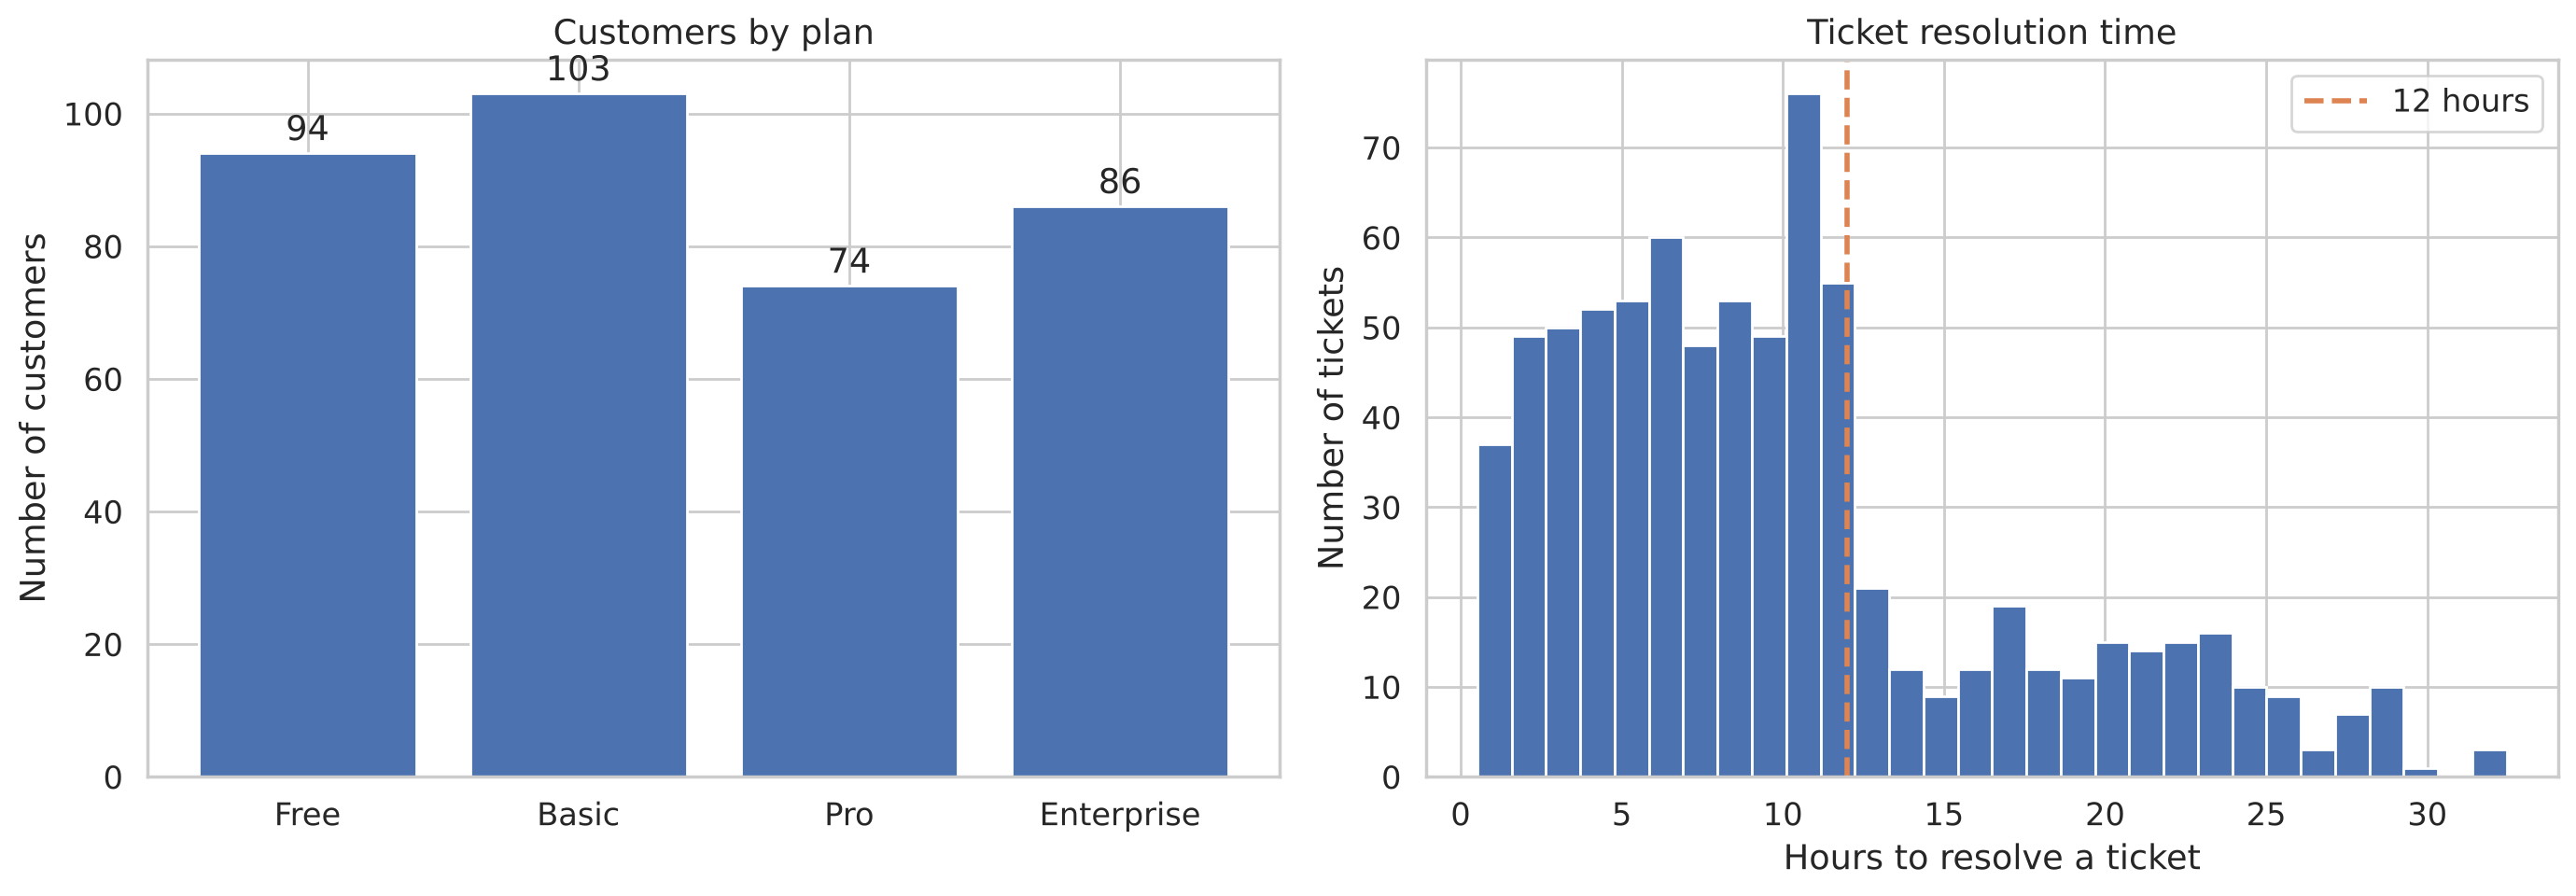

Overall churn rate: 27.2 %
Tickets resolved within 12 hours: 74.1 %


In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Bar chart: customers by plan
plan_counts = customers["plan"].value_counts().sort_index()
axes[0].bar(plan_counts.index.astype(str), plan_counts.values, color=STAYED)
for i, v in enumerate(plan_counts.values):
    axes[0].text(i, v + 2, str(v), ha="center")
axes[0].set_title("Customers by plan")
axes[0].set_ylabel("Number of customers")

# Histogram: resolution time of each ticket
axes[1].hist(support["resolution_time_hours"], bins=30, color=STAYED, edgecolor="white")
axes[1].axvline(12, color=CHURNED, linestyle="--", linewidth=2, label="12 hours")
axes[1].set_title("Ticket resolution time")
axes[1].set_xlabel("Hours to resolve a ticket")
axes[1].set_ylabel("Number of tickets")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Overall churn rate:", round(customers["churned"].mean() * 100, 1), "%")
print("Tickets resolved within 12 hours:", round((support["resolution_time_hours"] <= 12).mean() * 100, 1), "%")

**Customers by plan (bar chart).** The customer base is spread fairly evenly across the four plans. Basic is the largest (103 customers) and Pro the smallest (74). This matters because no single plan dominates the overall churn figure.

**Ticket resolution time (histogram).** Most tickets are closed within half a day (median 8.7 hours), but the distribution has a long tail to the right. **25.9% of tickets take more than 12 hours**, and some take more than a day. This tail is the group I investigate below.

Across all customers the **churn rate is 27.2%**.

### 2.2 Relationships between variables

**Plan type and engagement**

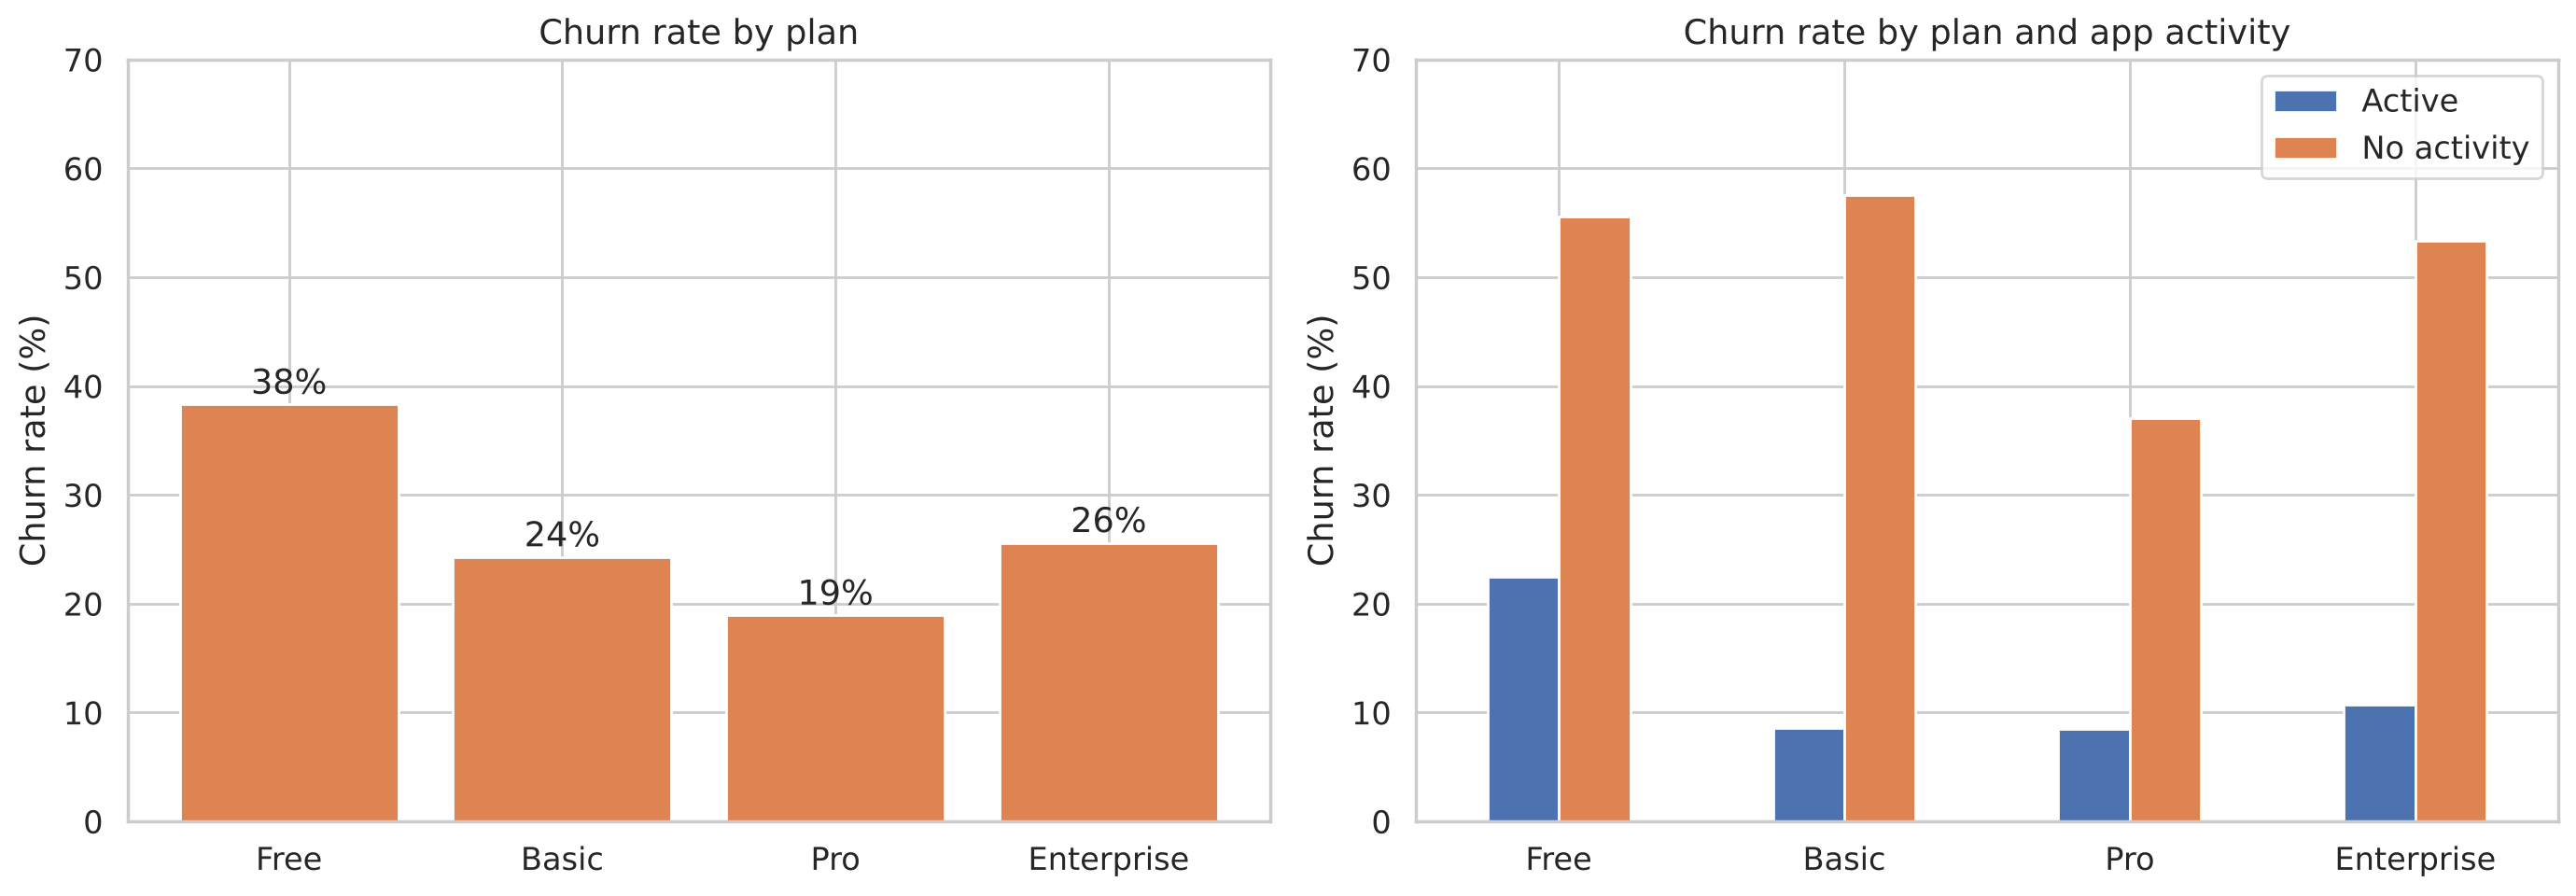

              mean  count
engagement               
Active       0.122    222
No activity  0.519    135


In [12]:
plan_churn = customers.groupby("plan", observed=True)["churned"].mean() * 100
engaged_churn = (customers.groupby(["plan", "engagement"], observed=True)["churned"].mean() * 100).unstack()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(plan_churn.index.astype(str), plan_churn.values, color=CHURNED)
for i, v in enumerate(plan_churn.values):
    axes[0].text(i, v + 1, f"{v:.0f}%", ha="center")
axes[0].set_title("Churn rate by plan")
axes[0].set_ylabel("Churn rate (%)")
axes[0].set_ylim(0, 70)

engaged_churn[["Active", "No activity"]].plot(kind="bar", ax=axes[1], color=[STAYED, CHURNED], rot=0)
axes[1].set_title("Churn rate by plan and app activity")
axes[1].set_ylabel("Churn rate (%)")
axes[1].set_xlabel("")
axes[1].set_ylim(0, 70)
axes[1].legend(title="")

plt.tight_layout()
plt.show()

print(customers.groupby("engagement")["churned"].agg(["mean", "count"]).round(3))

Looking at plan type alone, **Free users churn the most (38%)** and Pro users the least (19%).

Adding engagement changes the picture. **In every plan, customers with no activity churn far more than active ones**: overall 51.9% against 12.2%. For paid plans the difference is large, for example Basic goes from 9% (active) to 58% (no activity). The more a customer uses the app, the less likely they are to leave: churn falls from 52% with no events to 21% with one event and around 5% with two or more.

Free users also have the lowest share of active customers (52%, against 64-68% on paid plans). So part of the high churn on Free is explained by low engagement, not by the plan itself.

**Support activity and churn**

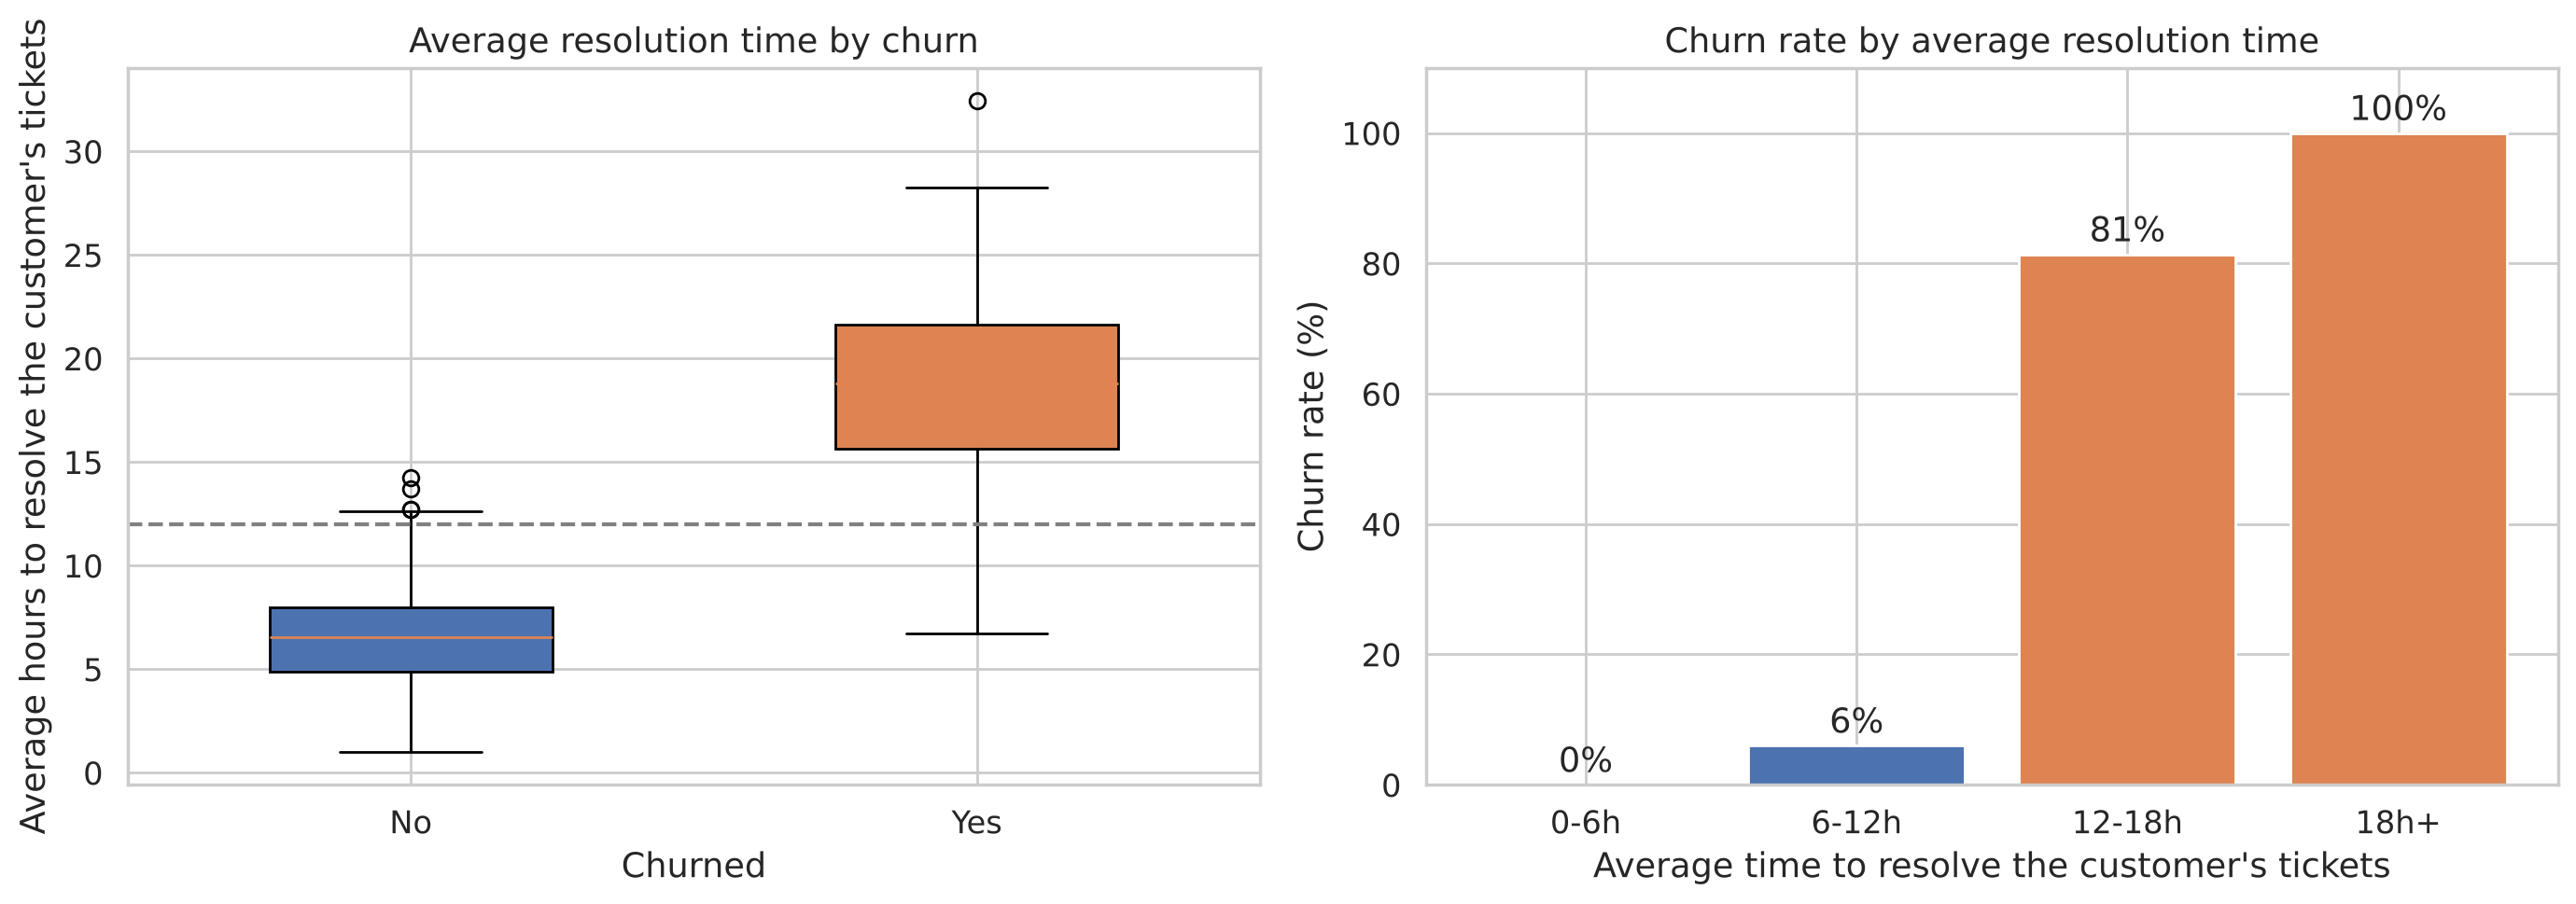

                mean  count
support_speed              
12h or less    0.034    232
More than 12h  0.913     92


In [13]:
with_tickets = customers.dropna(subset=["avg_resolution_hours"])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

box = axes[0].boxplot([with_tickets.loc[with_tickets["churn"] == g, "avg_resolution_hours"] for g in ["No", "Yes"]],
                      patch_artist=True, widths=0.5)
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels(["No", "Yes"])
for patch, colour in zip(box["boxes"], [STAYED, CHURNED]):
    patch.set_facecolor(colour)
axes[0].axhline(12, color="grey", linestyle="--")
axes[0].set_title("Average resolution time by churn")
axes[0].set_xlabel("Churned")
axes[0].set_ylabel("Average hours to resolve the customer's tickets")

bands = pd.cut(with_tickets["avg_resolution_hours"], [0, 6, 12, 18, np.inf],
               labels=["0-6h", "6-12h", "12-18h", "18h+"])
band_churn = with_tickets.groupby(bands, observed=True)["churned"].mean() * 100
axes[1].bar(band_churn.index.astype(str), band_churn.values,
            color=[STAYED, STAYED, CHURNED, CHURNED])
for i, v in enumerate(band_churn.values):
    axes[1].text(i, v + 2, f"{v:.0f}%", ha="center")
axes[1].set_title("Churn rate by average resolution time")
axes[1].set_xlabel("Average time to resolve the customer's tickets")
axes[1].set_ylabel("Churn rate (%)")
axes[1].set_ylim(0, 110)

plt.tight_layout()
plt.show()

print(customers.groupby("support_speed", observed=True)["churned"].agg(["mean", "count"]).round(3))

This is the clearest pattern in the data. Customers who churned waited much longer for support: their average resolution time is mostly above 12 hours, while customers who stayed are mostly below it.

The bar chart shows a sharp break at 12 hours:

- 0-6 hours: **0%** churn
- 6-12 hours: **6%** churn
- 12-18 hours: **81%** churn
- more than 18 hours: **100%** churn

Overall, customers whose tickets take more than 12 hours on average churn at **91.3%**, against **3.4%** below that line. I also looked at ticket topic and channel. Churn is similar across them (billing is slightly higher), so the problem is how long customers wait, not why they contact us or how.

**Bringing the sources together**

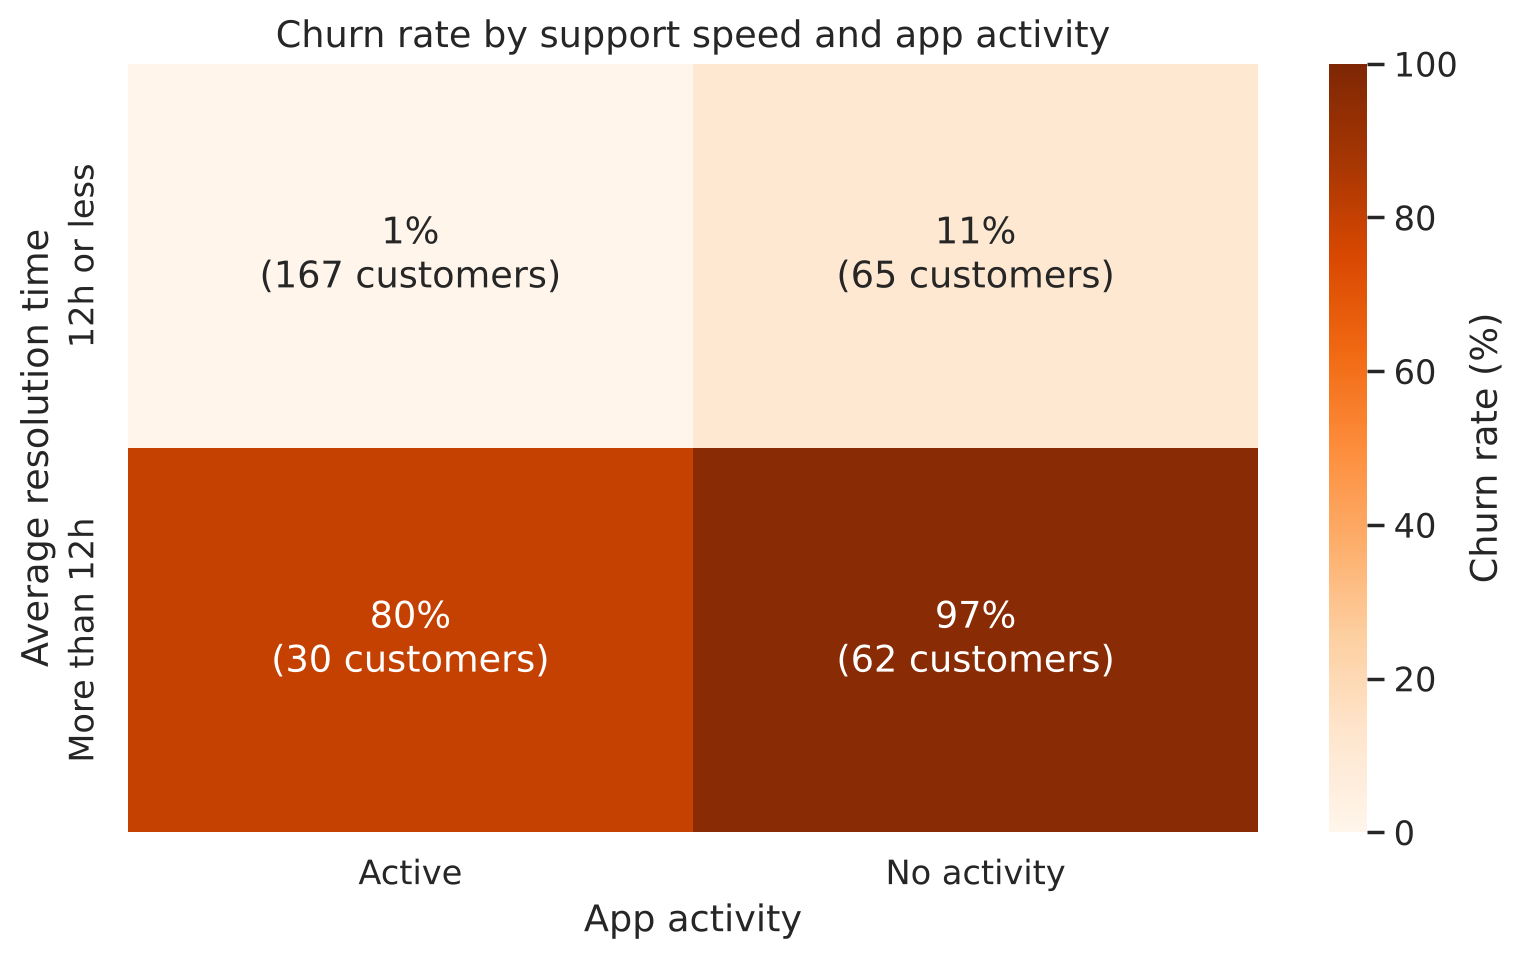

Churned customers: 97
  with slow support: 84
  with no activity: 70
  with at least one of the two: 94


In [14]:
combo = (customers.dropna(subset=["support_speed"])
         .groupby(["support_speed", "engagement"], observed=True)["churned"]
         .agg(["mean", "count"]).reset_index())
combo["churn_rate"] = combo["mean"] * 100

pivot = combo.pivot(index="support_speed", columns="engagement", values="churn_rate")
counts = combo.pivot(index="support_speed", columns="engagement", values="count")

fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(pivot, annot=pivot.round(0).astype(int).astype(str) + "%\n(" + counts.astype(str) + " customers)",
            fmt="", cmap="Oranges", vmin=0, vmax=100, cbar_kws={"label": "Churn rate (%)"}, ax=ax)
ax.set_title("Churn rate by support speed and app activity")
ax.set_xlabel("App activity")
ax.set_ylabel("Average resolution time")
plt.tight_layout()
plt.show()

churners = customers[customers["churned"] == 1]
slow = churners["support_speed"] == "More than 12h"
inactive = churners["engagement"] == "No activity"
print("Churned customers:", len(churners))
print("  with slow support:", slow.sum())
print("  with no activity:", inactive.sum())
print("  with at least one of the two:", (slow | inactive).sum())

When I combine support and engagement, the two factors work together:

- Active customers with fast support almost never leave (**less than 1%** churn, 1 of 167).
- Customers with **no activity and slow support** churn at **97%**.
- Slow support alone is already very damaging: even active customers with slow support churn at 80%.

**94 of the 97 churned customers (97%) had slow support, no app activity, or both.** This is why the findings had to come from joining the three sources: no single table would show it.

**Limits of the data.** The data does not include the date a customer cancelled, so I cannot confirm that slow support happened before the cancellation, and I cannot measure the trend in churn over the two quarters. These are strong associations, not proven causes. Adding a cancellation date and the missing `signup_date` would make the next analysis stronger.

### 2.3 Revenue at risk

In [15]:
paid = customers[customers["plan"] != "Free"]
lost = paid[paid["churned"] == 1].groupby("plan", observed=True)["plan_list_price"].sum()
total = paid.groupby("plan", observed=True)["plan_list_price"].sum()
print(pd.DataFrame({"price_of_churned_customers": lost, "price_of_all_customers": total,
                    "share_lost_%": (lost / total * 100).round(1)}))
print("Total share lost:", round(lost.sum() / total.sum() * 100, 1), "%")

            price_of_churned_customers  price_of_all_customers  share_lost_%
plan                                                                        
Basic                              506                    2085          24.3
Pro                                726                    4037          18.0
Enterprise                        2697                   10037          26.9
Total share lost: 24.3 %


Churned customers account for **24.3% of the total plan value** (3,929 of 16,159 in list price). Enterprise customers make up most of it (2,697), so although Enterprise churn is close to average, these are the most expensive customers to lose.

## 3. Metric for the business to monitor

The strongest driver of churn is something the business controls directly: how quickly support resolves tickets. I recommend monitoring:

**12-hour resolution rate = tickets resolved within 12 hours / all tickets received, per month.**

Why this metric:

- It reacts quickly. Churn only shows a problem after the customer has left, while this metric shows it while there is still time to act.
- The 12-hour line is where churn jumps from 6% to 81% in the data.
- The support team can own it and improve it directly.

As a second, supporting metric I recommend the **active customer rate**: the share of customers with at least one activity event in the month. Customers with no activity are the group to contact first.

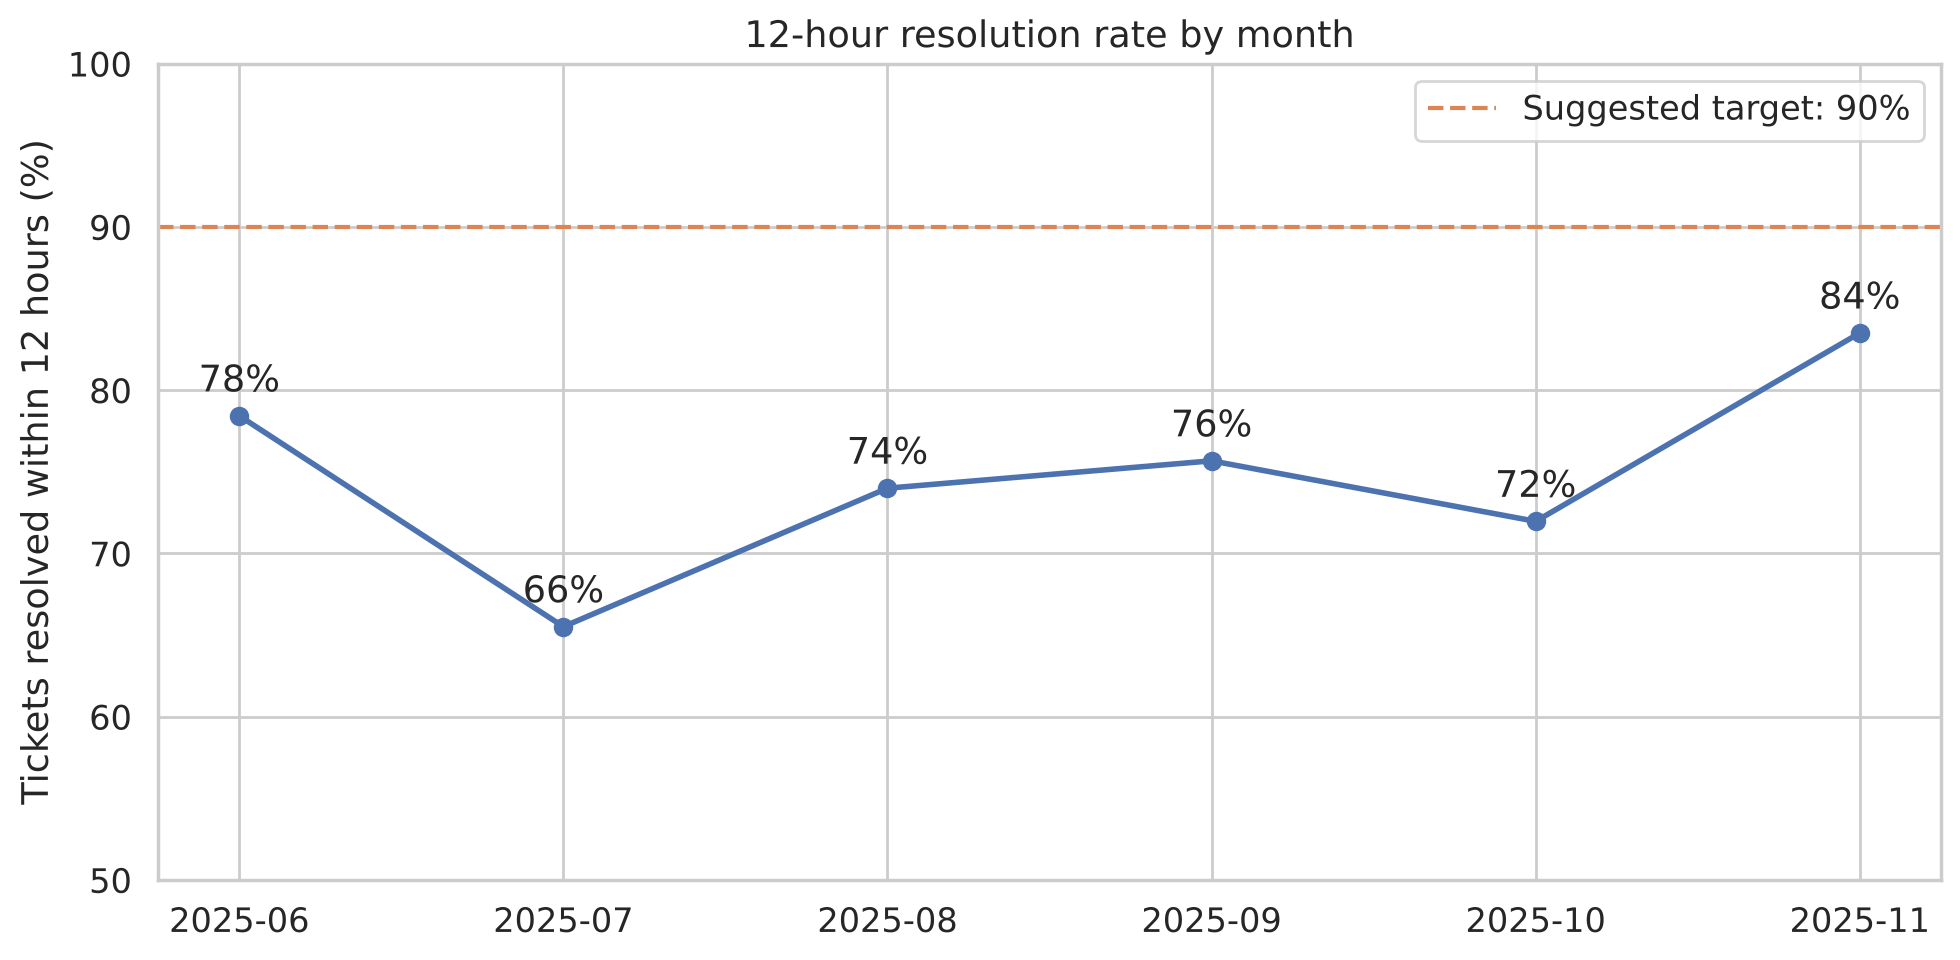

Baseline 12-hour resolution rate: 74.1%
Baseline active customer rate (whole period): 62.2%
Baseline churn rate: 27.2%


In [16]:
support["month"] = support["ticket_time"].dt.to_period("M")
monthly = support.groupby("month")["resolution_time_hours"].agg(
    tickets="size", within_12h=lambda x: (x <= 12).mean() * 100)
# December only has one day of data, so it is excluded from the monthly trend
monthly = monthly[monthly.index < pd.Period("2025-12", "M")]

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly.index.astype(str), monthly["within_12h"], marker="o", color=STAYED, linewidth=2)
ax.axhline(90, color=CHURNED, linestyle="--", label="Suggested target: 90%")
for x, y in zip(monthly.index.astype(str), monthly["within_12h"]):
    ax.text(x, y + 1.5, f"{y:.0f}%", ha="center")
ax.set_ylim(50, 100)
ax.set_title("12-hour resolution rate by month")
ax.set_ylabel("Tickets resolved within 12 hours (%)")
ax.legend()
plt.tight_layout()
plt.show()

baseline = (support["resolution_time_hours"] <= 12).mean() * 100
active_rate = (customers["n_events"] > 0).mean() * 100
print(f"Baseline 12-hour resolution rate: {baseline:.1f}%")
print(f"Baseline active customer rate (whole period): {active_rate:.1f}%")
print(f"Baseline churn rate: {customers['churned'].mean() * 100:.1f}%")

**Current values (baseline):**

- **12-hour resolution rate: 74.1%.** One in four tickets currently takes more than 12 hours. It moved between 66% (July) and 84% (November).
- **Active customer rate: 62.2%** of customers had at least one activity event in the period.
- **Churn rate: 27.2%**, kept as the outcome metric that shows whether the actions are working.

**How to use it:** the support team reviews the 12-hour resolution rate every month, with a target of 90%. Any month below 75% should trigger a review of staffing and of tickets that are still open after 8 hours. Leadership can then check, quarter by quarter, whether churn falls as the resolution rate rises.

## 4. Final summary and recommendations

Fit.ly's churn is mainly linked to two things the business can act on: **slow support** and **low engagement**. Together they cover 94 of the 97 churned customers. Plan type has a smaller effect: Free users churn the most, but this is mostly because they use the app less and wait longer for support.

**Recommendations for next quarter:**

1. **Set a 12-hour resolution target for support tickets.** Track the 12-hour resolution rate monthly, aim for 90% (from 74% today), and escalate any ticket still open after 8 hours. This addresses the factor most strongly linked to churn.
2. **Prioritise tickets from at-risk customers.** Customers with no recent app activity who open a ticket are the most likely to leave (97% churn when support is also slow). Route these tickets, and those from Enterprise customers, to the front of the queue.
3. **Re-engage inactive customers early.** Contact customers with no activity in their first weeks, for example with a guided first workout or a reminder campaign. Moving a customer from zero to two events is linked to churn falling from 52% to about 5%.
4. **Use the Free plan as an onboarding opportunity.** Free users are the least engaged. Better onboarding for them can reduce churn and create more upgrade opportunities.
5. **Fix the data gaps.** Add the `signup_date` and a cancellation date, fix the `state` field in the support system, and confirm that GDPR deletion requests are processed in the source systems. This will let us track churn over time and confirm cause and effect.